Basic ML (1 real input and 1 real output) - Polinomial regression + Regularization

In [92]:
import numpy as np # numerical things
import numpy.matlib as nml # matricial computations
import matplotlib.pyplot as plt # plots

In [93]:
np.random.seed(13)

In [94]:
def oracle(x):
  return x**2

In [95]:
n = 5
sigma = 0.1
nt = 1000

In [96]:
x = np.random.rand(n)
y = oracle(x) + sigma * np.random.randn(n)
xt = np.linspace(0,1,nt)
yt = oracle(xt)

In [97]:
x = np.asmatrix(x).transpose()
y = np.asmatrix(y).transpose()
xt = np.asmatrix(xt).transpose()
yt = np.asmatrix(yt).transpose()

In [98]:
# | X c - y | ^2 + lam c' M c
# I change the matrix M wrt to before
p = 10
lam = 0.00001
M = nml.zeros((p+1, p+1))

for i in range(2, p+1):
  for j in range(2, p+1):
    M[i,j] = i * (i-1) * j * (j-1) / (i+j-3)

M = nml.eye(p+1, p+1)
X = nml.ones((n,1))
Xt = nml.ones((nt,1))

for i in range (1, p+1):
  X = np.concatenate((X,np.power(x,i)), axis=1)
  Xt = np.concatenate((Xt,np.power(xt,i)), axis=1)
c = np.linalg.solve(X.T*X+lam*M, X.T*y)
yp = np.matmul(Xt,c)
err = np.mean(np.power(yt-yp,2))
print(str(p), "", str(err))

10  0.341619752427288


I've now modified my matrix M as nlm.eye(p+1, p+1).

This makes my model become | X c - y | ^2 + lam c' I c -> | X c - y | ^2 + lam |c|^2

1. With lam = 10000, I can see how my model is complitely flat (c is now equal to 0)
2. With lam =0.00001, I get a model that tries to fit all the data.

The complexity term c has an important impact on the behavior of the final result



lambda = 10000  

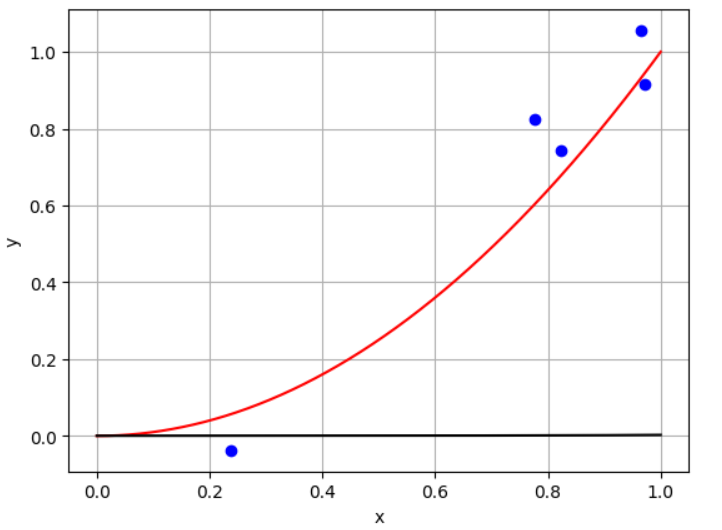

lambda = 1e-05  

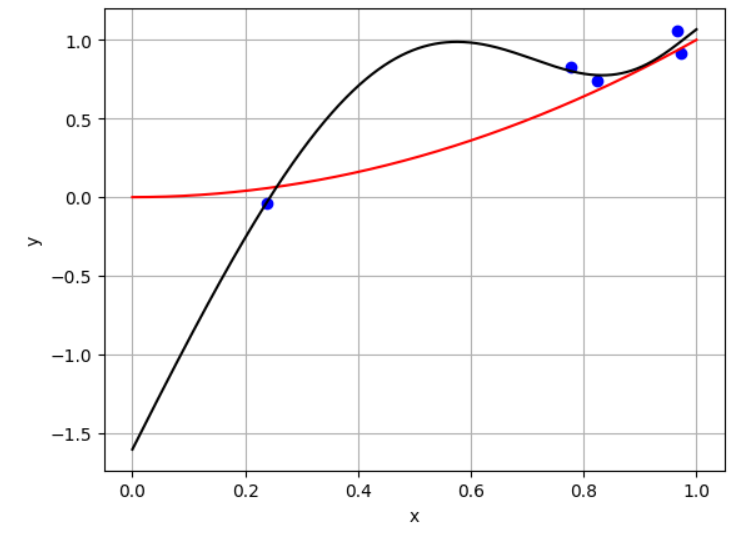

In [99]:
from IPython.display import Image, display

image_paths = [
    "/content/p10lam10000Mdiff.png",
    "/content/p10lam00001Mdiff.png"
]

lambda_arr = [10000, 0.00001]

for i, path in enumerate(image_paths):
    print(f"lambda = {lambda_arr[i]}", end="  ")
    display(Image(filename=path, width=200))

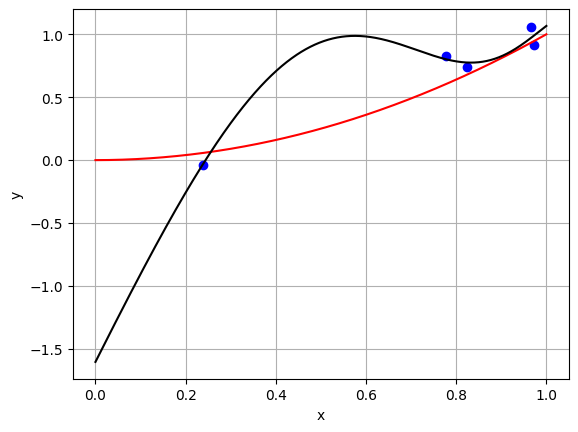

In [100]:
fig, ax = plt.subplots()
ax.plot(x,y, 'bo') # blue points
ax.plot(xt,yt, 'r') # red line for the model we created
ax.plot(xt,yp, 'k') # black line for what we actually have learnt
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.grid() # acrivate the grid
plt.show()